In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [5]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [6]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5) #* 0.2
b1 = torch.randn(n_hidden,                        generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01
b2 = torch.randn(vocab_size,                      generator=g) * 0

# BatchNorm parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12097


In [7]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  # BatchNorm layer
  # -------------------------------------------------------------
  bnmeani = hpreact.mean(0, keepdim=True)
  bnstdi = hpreact.std(0, keepdim=True)
  hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
  with torch.no_grad():
    bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
    bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
  # -------------------------------------------------------------
  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3147
  10000/ 200000: 2.1984
  20000/ 200000: 2.3375
  30000/ 200000: 2.4359
  40000/ 200000: 2.0119
  50000/ 200000: 2.2595
  60000/ 200000: 2.4775
  70000/ 200000: 2.1020
  80000/ 200000: 2.2788
  90000/ 200000: 2.1862
 100000/ 200000: 1.9474
 110000/ 200000: 2.3010
 120000/ 200000: 1.9837
 130000/ 200000: 2.4523
 140000/ 200000: 2.3839
 150000/ 200000: 2.1987
 160000/ 200000: 1.9733
 170000/ 200000: 1.8668
 180000/ 200000: 1.9973
 190000/ 200000: 1.8347


In [12]:
# expected loss of the function 
-torch.tensor(1/27.0).log()

tensor(3.2958)

In [19]:
# 4- dimensional example of the issue
logitsex = torch.tensor([1.0, 5.0, 10.0, 0.0])
probsex = torch.softmax(logitsex, dim=0)
lossex = -probsex[2].log()
probsex, lossex

(tensor([1.2256e-04, 6.6917e-03, 9.9314e-01, 4.5089e-05]), tensor(0.0069))

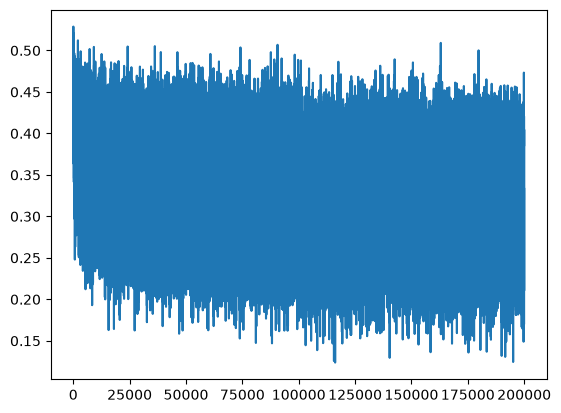

In [8]:
plt.plot(lossi)

In [9]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1  + b1
  #hpreact = bngain * (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.06659197807312
val 2.1050572395324707


In [10]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      emb = C[torch.tensor([context])] # (1,block_size,n_embd)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      # samle from the distribution
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # Shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' toekn, break
      if ix == 0:
         break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

carpahzarbriq.
shlimrixtts.
lusslaysierricnenddhn.
frtivgqliyah.
farrichaiirdnsleggyu.
bmanvitte.
sants.
lustvi.
vabbuwatth.
giidryxiidh.
sulipsables.
falia.
gtas.
jasfaylahas.
bduricsydustquovozswy.
bjumillassannyks.
sadlusoffordst.
sramsryndlycpllmanraq.
shelseombriyabhda.
ffxrdustvebndvi.


In [20]:
h

tensor([[-0.6220,  0.6934, -0.7763, -0.3628, -0.5019, -0.9714,  0.2481, -0.9996,
          0.9995,  0.9609,  0.9918, -0.6092,  0.9999, -0.9900, -0.9984, -0.9425,
          0.2466,  0.9969,  0.3388, -0.7889, -0.7720,  0.9697,  0.7807,  0.9505,
          0.9864, -0.1669,  0.9544, -0.9721, -0.9147,  0.8666,  0.9964,  0.9016,
          0.9162, -0.6464,  0.4525, -0.8157,  0.8274,  0.2200, -0.9074, -0.9999,
         -0.5891, -0.8632, -1.0000, -0.8827,  0.9970, -0.8768,  0.9997, -0.0413,
          0.9991,  0.9978, -0.9893, -0.9993, -0.4086,  0.8193,  0.9107,  0.7962,
          0.9619,  0.9882, -0.4104, -0.9456,  0.9991, -0.6639,  0.9544, -0.9463,
         -0.9730,  0.8123, -0.9996, -0.9960, -0.9961, -0.9357, -0.9993, -0.7936,
         -0.7801, -0.9637, -1.0000, -0.5059, -0.9785,  0.6597,  0.9716,  0.6752,
          0.9154, -0.9999,  0.4388,  0.7953,  0.3132,  0.9982, -0.8692,  0.9983,
         -0.9889, -0.6453,  0.9081,  0.9335, -0.9635,  0.9631, -0.9967,  0.0123,
         -0.8154,  0.9839,  

(array([37.,  7.,  7.,  4.,  2.,  7.,  0.,  4.,  3.,  4.,  1.,  0.,  5.,
         0.,  2.,  3.,  0.,  1.,  1.,  1.,  2.,  1.,  0.,  1.,  0.,  1.,
         1.,  0.,  1.,  0.,  3.,  3.,  1.,  1.,  0.,  1.,  1.,  0.,  3.,
         0.,  1.,  3.,  2.,  2.,  9.,  4.,  5.,  7., 10., 48.]),
 array([-9.99998391e-01, -9.59998492e-01, -9.19998593e-01, -8.79998695e-01,
        -8.39998796e-01, -7.99998897e-01, -7.59998999e-01, -7.19999100e-01,
        -6.79999201e-01, -6.39999303e-01, -5.99999404e-01, -5.59999505e-01,
        -5.19999607e-01, -4.79999708e-01, -4.39999809e-01, -3.99999911e-01,
        -3.60000012e-01, -3.20000113e-01, -2.80000215e-01, -2.40000316e-01,
        -2.00000417e-01, -1.60000519e-01, -1.20000620e-01, -8.00007212e-02,
        -4.00008225e-02, -9.23871994e-07,  3.99989748e-02,  7.99988735e-02,
         1.19998772e-01,  1.59998671e-01,  1.99998569e-01,  2.39998468e-01,
         2.79998367e-01,  3.19998266e-01,  3.59998164e-01,  3.99998063e-01,
         4.39997962e-01,  4.7999

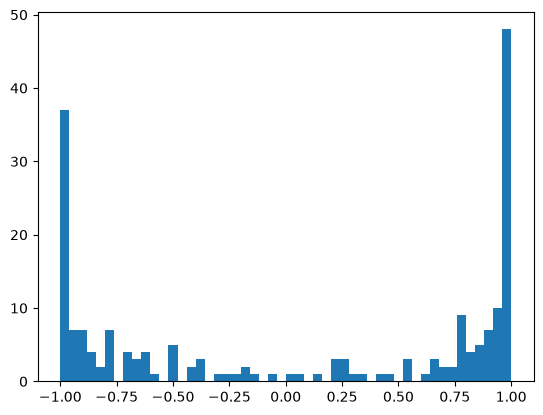

In [21]:
plt.hist(h.view(-1).tolist(), 50)

(array([  1.,   0.,   0.,   0.,   2.,   1.,   1.,   2.,   4.,  11.,  14.,
         18.,  13.,  19.,  42.,  54.,  66.,  84., 103., 123., 170., 216.,
        262., 273., 347., 423., 524., 599., 537., 456., 416., 323., 247.,
        240., 185., 148., 129.,  81.,  82.,  57.,  39.,  29.,  19.,  16.,
         11.,   5.,   3.,   2.,   1.,   2.]),
 array([-6.35468864, -6.12597466, -5.89726067, -5.66854668, -5.43983269,
        -5.2111187 , -4.98240471, -4.75369072, -4.52497673, -4.29626274,
        -4.06754875, -3.83883476, -3.61012077, -3.38140678, -3.15269279,
        -2.92397881, -2.69526482, -2.46655083, -2.23783684, -2.00912285,
        -1.78040886, -1.55169487, -1.32298088, -1.09426689, -0.8655529 ,
        -0.63683891, -0.40812492, -0.17941093,  0.04930305,  0.27801704,
         0.50673103,  0.73544502,  0.96415901,  1.192873  ,  1.42158699,
         1.65030098,  1.87901497,  2.10772896,  2.33644295,  2.56515694,
         2.79387093,  3.02258492,  3.2512989 ,  3.48001289,  3.70872688,
 

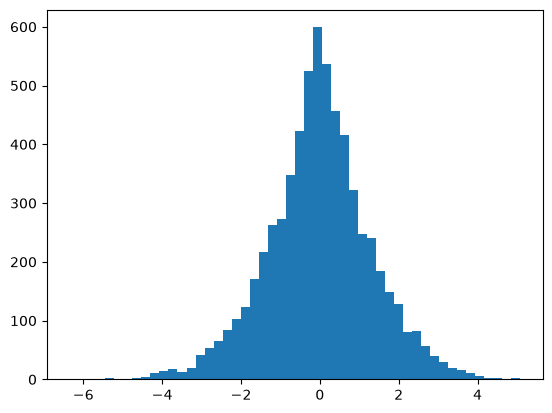

In [ ]:
plt.hist(hpreact.view(-1).tolist(), 50 )

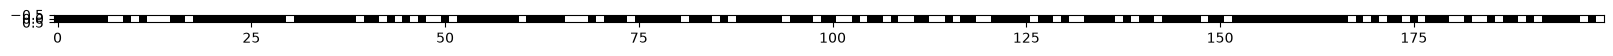

In [23]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

tensor(0.0011) tensor(0.9893)
tensor(0.0024) tensor(3.1385)


(array([6.64292846e-06, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        6.64292846e-06, 1.32858569e-05, 4.65004992e-05, 4.65004992e-05,
        1.06286855e-04, 1.19572712e-04, 2.72360067e-04, 3.78646922e-04,
        6.11149418e-04, 1.22894176e-03, 1.89987754e-03, 3.20853444e-03,
        5.39405791e-03, 8.20401664e-03, 1.29470676e-02, 2.02808606e-02,
        3.03382543e-02, 4.21427381e-02, 6.16397331e-02, 8.13758736e-02,
        1.02500386e-01, 1.22515530e-01, 1.34997592e-01, 1.37382403e-01,
        1.29105315e-01, 1.12923141e-01, 9.10081198e-02, 7.07006876e-02,
        5.22599182e-02, 3.58452419e-02, 2.43330469e-02, 1.65940353e-02,
        1.09409032e-02, 6.68942895e-03, 4.05218636e-03, 2.64388553e-03,
        1.50130183e-03, 9.03438270e-04, 5.84577704e-04, 4.31790350e-04,
        2.05930782e-04, 7.30722130e-05, 6.64292846e-05, 3.32146423e-05,
        0.00000000e+00, 2.65717138e-05]),
 array([-20.5114994 , -19.75881931, -19.00613922, -18.25345913,
        -17.50077904, -16.7480

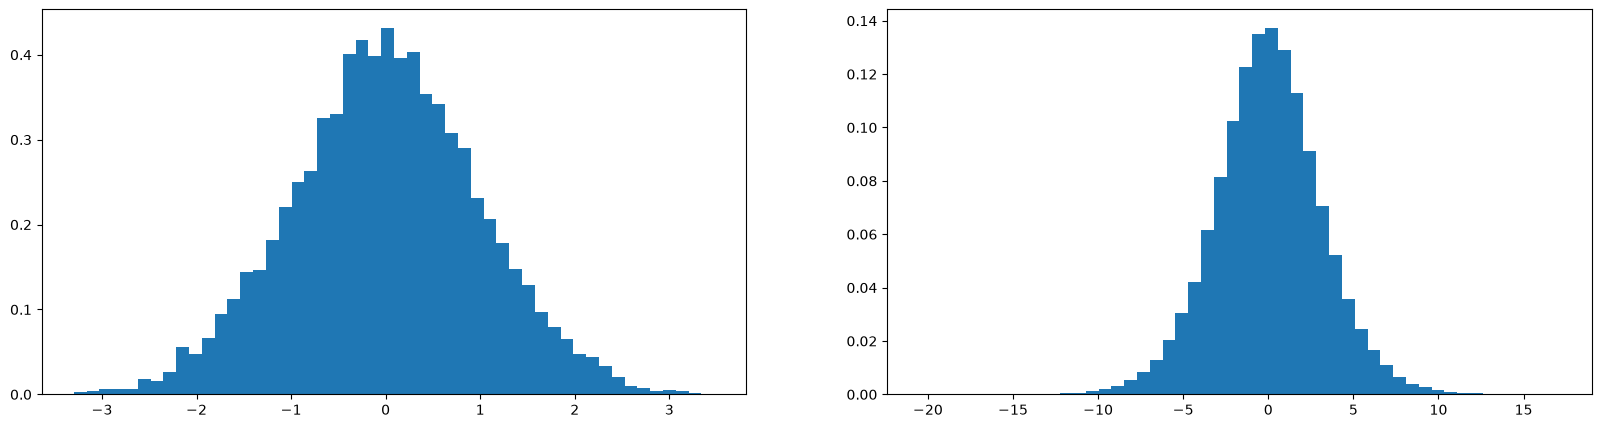

In [27]:
# setting up scaling to optimise the network
x = torch.randn(1000, 10)
w = torch.randn(10, 200)
y = x @ w

print(x.mean(), x.std())
print(y.mean(), y.std())
plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True)